# Pressing in StatsBomb Open Data

Follow a press from the event and 360 freeze frame through the 26 SPN inputs to its predicted outcome. A second score compares an individual presser’s observed position with feasible alternatives. The tables and figures below are saved from the three featured matches.

## Select matches · StatsBomb Open Data

Set `MATCH_IDS = None` to run every match with event and 360 coverage in the chosen competition and season. The three defaults are 2022 World Cup group games. Their event and 360 records are saved under `output/sample/` for reuse by the following steps. [Data supplied by StatsBomb](https://github.com/statsbomb/open-data) · [Notebook installation](../README.md#sample-workflow)

In [1]:
from pathlib import Path
import json
import sys
import warnings

import pandas as pd
from IPython.display import Image, Markdown, display
from statsbombpy import sb
from statsbombpy.api_client import NoAuthWarning

COMPETITION_ID, SEASON_ID = 43, 106
MATCH_IDS = [3857272, 3857279, 3857289]
INCLUDE_COMPARISONS = False

root = Path.cwd()
if root.name == "tests":
    root = root.parent
sys.path.insert(0, str(root))
sample_dir = root / "output" / "sample"
events_dir = sample_dir / "events"
frames_dir = sample_dir / "three-sixty"
matches_dir = sample_dir / "matches"
for directory in (events_dir, frames_dir, matches_dir):
    directory.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", category=NoAuthWarning)
catalogue = sb.matches(COMPETITION_ID, SEASON_ID, fmt="dict", creds={})
available = {i: m for i, m in catalogue.items()
             if m.get("match_status") == m.get("match_status_360") == "available"}
selected = sorted(available) if MATCH_IDS is None else list(dict.fromkeys(MATCH_IDS))
if not selected:
    raise ValueError("Select at least one match with event and 360 coverage.")
unavailable = set(selected) - available.keys()
if unavailable:
    raise ValueError(f"These matches lack paired data in the selected season: {sorted(unavailable)}")

fixtures = {str(i): available[i] for i in selected}
fixture_table = pd.DataFrame([
    {"match_id": mid, "date": m["match_date"], "home": m["home_team"]["home_team_name"],
     "away": m["away_team"]["away_team_name"], "stage": m["competition_stage"]["name"],
     "events": m["match_status"], "360": m["match_status_360"]}
    for mid, m in fixtures.items()
]).set_index("match_id")
display(fixture_table)

for mid in fixtures:
    events = list(sb.events(match_id=int(mid), fmt="dict", creds={}).values())
    frames = sb.frames(match_id=int(mid), fmt="dict", creds={})
    (events_dir / f"{mid}.json").write_text(json.dumps(events), encoding="utf-8")
    (frames_dir / f"{mid}.json").write_text(json.dumps(frames), encoding="utf-8")

,date,home,away,stage,events,360
match_id,,,,,,
3857272,2022-11-25,England,United States,Group Stage,available,available
3857279,2022-11-22,France,Australia,Group Stage,available,available
3857289,2022-11-26,Argentina,Mexico,Group Stage,available,available


## Read the match and label pressure sequences · `spn.data_processing`

An **anchor** is a ball-side event at which SPN detects high pressure. Consecutive anchors can belong to one sequence. Read the example down the rows to see when the press continued, how it ended and which outcome the pressing team received. Times are relative to the period.

In [2]:
from spn.data_processing import LabelConfig, SequenceConfig, build_sequences_from_match, load_match_data
from spn.model import SPNModel
from spn.networks import PressureParams

model = SPNModel()
params = PressureParams(**model.config["pressure"])
sequence_config = SequenceConfig(**model.config["sequence"])
label_config = LabelConfig(**model.config["labels"])

def read_match(mid):
    return load_match_data(events_dir / f"{mid}.json", frames_dir / f"{mid}.json", match_id=mid)

anchors, labels, counts = {}, {}, []
for mid in fixtures:
    match = read_match(mid)
    anchors[mid], labels[mid] = build_sequences_from_match(match, sequence_config, params, label_config)
    counts.append({"match_id": mid, "events": len(match.events), "usable_frames": len(match.frames),
                   "anchors": len(anchors[mid]), "sequences": anchors[mid].seq_id.nunique()})
display(pd.DataFrame(counts).set_index("match_id"))

all_labels = pd.concat(labels.values(), ignore_index=True)
onsets = all_labels.loc[all_labels.is_onset.eq(True) & all_labels.value_model_eligible.eq(True)]
multiple = onsets.loc[onsets.anchor_count.gt(1)]
example = (multiple if not multiple.empty else onsets).head(1)

def example_rows(table):
    keys = ["match_id", "seq_id"]
    return table.merge(example[keys], on=keys).sort_values("ev_pos")

display(example_rows(all_labels)[["match_id", "seq_id", "ev_pos", "period", "timestamp", "event_type",
                                 "press_team_name", "state", "outcome_tag"]])

,events,usable_frames,anchors,sequences
match_id,,,,
3857272,3519,3166,240,128
3857279,3963,3509,197,120
3857289,3375,2751,160,89


,match_id,seq_id,ev_pos,period,timestamp,event_type,press_team_name,state,outcome_tag
0,3857272,1,0,1,00:01:05.317,Pass,England,continued_pressure,fail
1,3857272,1,1,1,00:01:06.102,Carry,England,continued_pressure,fail
2,3857272,1,2,1,00:01:06.112,Pass,England,continued_pressure,fail
3,3857272,1,3,1,00:01:07.110,Pass,England,continued_pressure,fail
4,3857272,1,4,1,00:01:09.980,Carry,England,crossed_half,fail


## Inspect one freeze frame · `spn.networks`

At the first anchor of the example sequence, a pressure edge links a defender to a target. A passing option links the carrier to a visible teammate. The network below includes the carrier’s location in metres on the 105 × 68 m pitch.

In [3]:
from spn.networks import build_spn_network

if example.empty:
    print("No resolved sequence to illustrate in this selection.")
else:
    onset = example.iloc[0]
    match = read_match(onset.match_id)
    event = match.events[int(onset.raw_event_position)]
    try:
        network = build_spn_network(event, match.frames[onset.anchor_event_id], params)
    except ValueError as error:
        print(f"This anchor has no usable network: {error}")
    else:
        x, y = network["xy"][network["carrier"]]
        display(pd.DataFrame([{
            "anchor_event_id": onset.anchor_event_id, "carrier": event.get("player", {}).get("name"),
            "x_m": x, "y_m": y, "defenders": len(network["defenders"]),
            "pressure_edges": len(network["pressure_edges"]), "passing_options": len(network["passes"]),
        }]))

,anchor_event_id,carrier,x_m,y_m,defenders,pressure_edges,passing_options
0,23e95ee0-a3a4-416e-88ff-9698b3bc92c3,Tyler Adams,19.775,60.69,8,24,9


## Measure the 26 inputs · `spn.feature_engineering`

A sequence enters the model when its outcome is resolved and every anchor has a usable network. The first table counts the exclusions. The second shows the 26 values at the example onset, in model order. Missing geometry or context stays missing. [Feature definitions and units](../spn/MODEL.md)

In [4]:
from spn.feature_engineering import build_feature_table

features = {mid: build_feature_table(read_match(mid), anchors[mid], labels[mid], params=params)
            for mid in fixtures}
audit = pd.DataFrame({mid: table.attrs["s3_completeness_audit"] for mid, table in features.items()}).T
display(audit.rename_axis("match_id"))

example_features = example_rows(pd.concat(features.values(), ignore_index=True))
if example_features.empty:
    print("The selection has no scored anchor for the illustrated sequence.")
else:
    values = example_features.iloc[0][model.features]
    display(values.rename("value at onset").rename_axis("feature").to_frame())

,expected_anchors,expected_sequences,retained_anchors,excluded_incomplete_sequences,excluded_censored_sequences
match_id,,,,,
3857272,240,128,236,0,1
3857279,197,120,197,0,0
3857289,160,89,157,0,2


,value at onset
feature,
ball_in_dist,5.737859
ball_in_angle_cos,0.121997
carrier_x_norm,0.188333
d_carrier_x_norm_dt,0.006667
carrier_touchline_m,7.31
P_total,0.993351
d_P_total_dt,-0.002059
effective_pressers,3.933001
n_open_pass,3


## Predict the outcome at each anchor · `spn.model`

Each row estimates how the sequence will end for the pressing team, using information through that anchor. Compare the three calibrated probabilities down the sequence. The rule-derived outcome alongside them is observed later.

In [5]:
predictions = {mid: model.predict(table) for mid, table in features.items()}
example_predictions = example_rows(pd.concat(predictions.values(), ignore_index=True))
display(example_predictions.merge(
    example_features[["anchor_event_id", "timestamp", "event_type", "outcome_tag"]],
    on="anchor_event_id", validate="one_to_one",
)[["match_id", "seq_id", "ev_pos", "timestamp", "event_type", "p_fail", "p_neutral",
   "p_success", "predicted_class", "confidence", "outcome_tag"]].round(4))

,match_id,seq_id,ev_pos,timestamp,event_type,p_fail,p_neutral,p_success,predicted_class,confidence,outcome_tag
0,3857272,1,0,00:01:05.317,Pass,0.4860,0.2415,0.2725,fail,0.4860,fail
1,3857272,1,1,00:01:06.102,Carry,0.6659,0.1404,0.1937,fail,0.6659,fail
2,3857272,1,2,00:01:06.112,Pass,0.5278,0.1638,0.3084,fail,0.5278,fail
3,3857272,1,3,00:01:07.110,Pass,0.3533,0.3731,0.2736,neutral,0.3731,fail
4,3857272,1,4,00:01:09.980,Carry,0.3511,0.3779,0.2710,neutral,0.3779,fail


## Score the recorded presser · `spn.positioning`

This task starts from the original match. A scored row requires a named StatsBomb `Pressure` event, an identified carrier and feasible alternative positions under high pressure. The score in percentage points is 100 × (observed five-second regain probability − mean alternative regain probability). A positive value favours the observed position.

In [6]:
from spn.positioning import PositioningModel

position_model = PositioningModel()
pressures, named_scores = {}, []
for mid in fixtures:
    match = read_match(mid)
    pressures[mid] = position_model.predict(match)
    names = {e["id"]: (e.get("player") or {}).get("name") for e in match.events}
    named_scores.append(pressures[mid].assign(player=pressures[mid].event_id.map(names)))

display(pd.Series({mid: len(p) for mid, p in pressures.items()}, name="scored_pressures")
        .rename_axis("match_id").to_frame())
position_scores = pd.concat(named_scores, ignore_index=True)
display(position_scores[["match_id", "event_id", "player", "valid_alternatives", "observed_probability",
                         "alternative_probability", "position_quality_pp"]].head(10).round(4))

,scored_pressures
match_id,
3857272,2
3857279,1
3857289,1


,match_id,event_id,player,valid_alternatives,observed_probability,alternative_probability,position_quality_pp
0,3857272,6115ccac-c45f-4793-be0a-65283cff2f4d,Antonee Robinson,61,0.1840,0.1664,1.7625
1,3857272,c6fedfeb-c256-4f69-b6ee-415a54e7a10b,Giovanni Reyna,64,0.0887,0.0967,-0.8021
2,3857279,70a48151-21f3-4928-87a3-2c8fa923caca,Mitchell Thomas Duke,64,0.0463,0.0463,0.0033
3,3857289,5f28b3bb-9e4e-42c5-9b7e-9fcbe4e2afbd,Hirving Rodrigo Lozano Bahena,64,0.0816,0.0964,-1.4799


## Save the match tables and summarise teams · `spn.output`

Each match has a sequence table, anchor predictions, the 26 inputs, presser scores and a team summary. Team press value averages `p_success − p_fail` at sequence onset, giving each scored sequence one vote. The batch index tells the plotter which matches belong to this selection.

In [7]:
from spn.output import build_result, empty_result, save_features, save_result, team_values

batch, team_tables = [], []
for mid in fixtures:
    match = read_match(mid)
    if anchors[mid].empty:
        result = empty_result(match, model)
    else:
        result = build_result(match=match, sequences=anchors[mid], labels=labels[mid],
                              features=features[mid], predictions=predictions[mid], model=model)
    scored = pd.DataFrame(result["predictions"], columns=[
        "match_id", "seq_id", "ev_pos", "pressing_team_id", "p_success", "p_fail",
    ])
    teams = team_values(scored)
    result["teams"] = teams.to_dict("records")
    result["pressures"] = pressures[mid].to_dict("records")
    result["audit"]["position_count"] = len(pressures[mid])

    folder = matches_dir / mid
    save_result(result, folder)
    save_features(features[mid], model, folder)
    teams.to_csv(folder / "teams.csv", index=False)
    pressures[mid].to_csv(folder / "pressures.csv", index=False)
    batch.append({"match_id": mid, "status": result["status"], "prediction_count": len(scored),
                  "position_count": len(pressures[mid])})
    names = {e["team"]["id"]: e["team"]["name"] for e in match.events if e.get("team")}
    team_tables.append(teams.assign(match_id=mid, team=teams.pressing_team_id.map(names)))

(matches_dir / "batch_result.json").write_text(json.dumps(batch, indent=2), encoding="utf-8")
display(pd.concat(team_tables)[["match_id", "team", "presses", "expected_press_value"]].round(4))
print(f"Match tables: {matches_dir.relative_to(root)}")

,match_id,team,presses,expected_press_value
0,3857272,England,62,-0.2327
1,3857272,United States,65,-0.2769
0,3857279,France,62,-0.2737
1,3857279,Australia,58,-0.2700
0,3857289,Argentina,36,-0.2874
1,3857289,Mexico,51,-0.2551


Match tables: output/sample/matches


## Compare the selected teams and players · `spn.plotting`

The three rankings use the match tables above. Counts beside the values show how many scored sequences or pressures contribute. Change `INCLUDE_COMPARISONS` in the selection block to add press value versus xG difference and positioning versus competition points. The points comparison requires a single league or group stage with results.

### Expected press value by team · FIFA World Cup 2022 · 3 selected matches

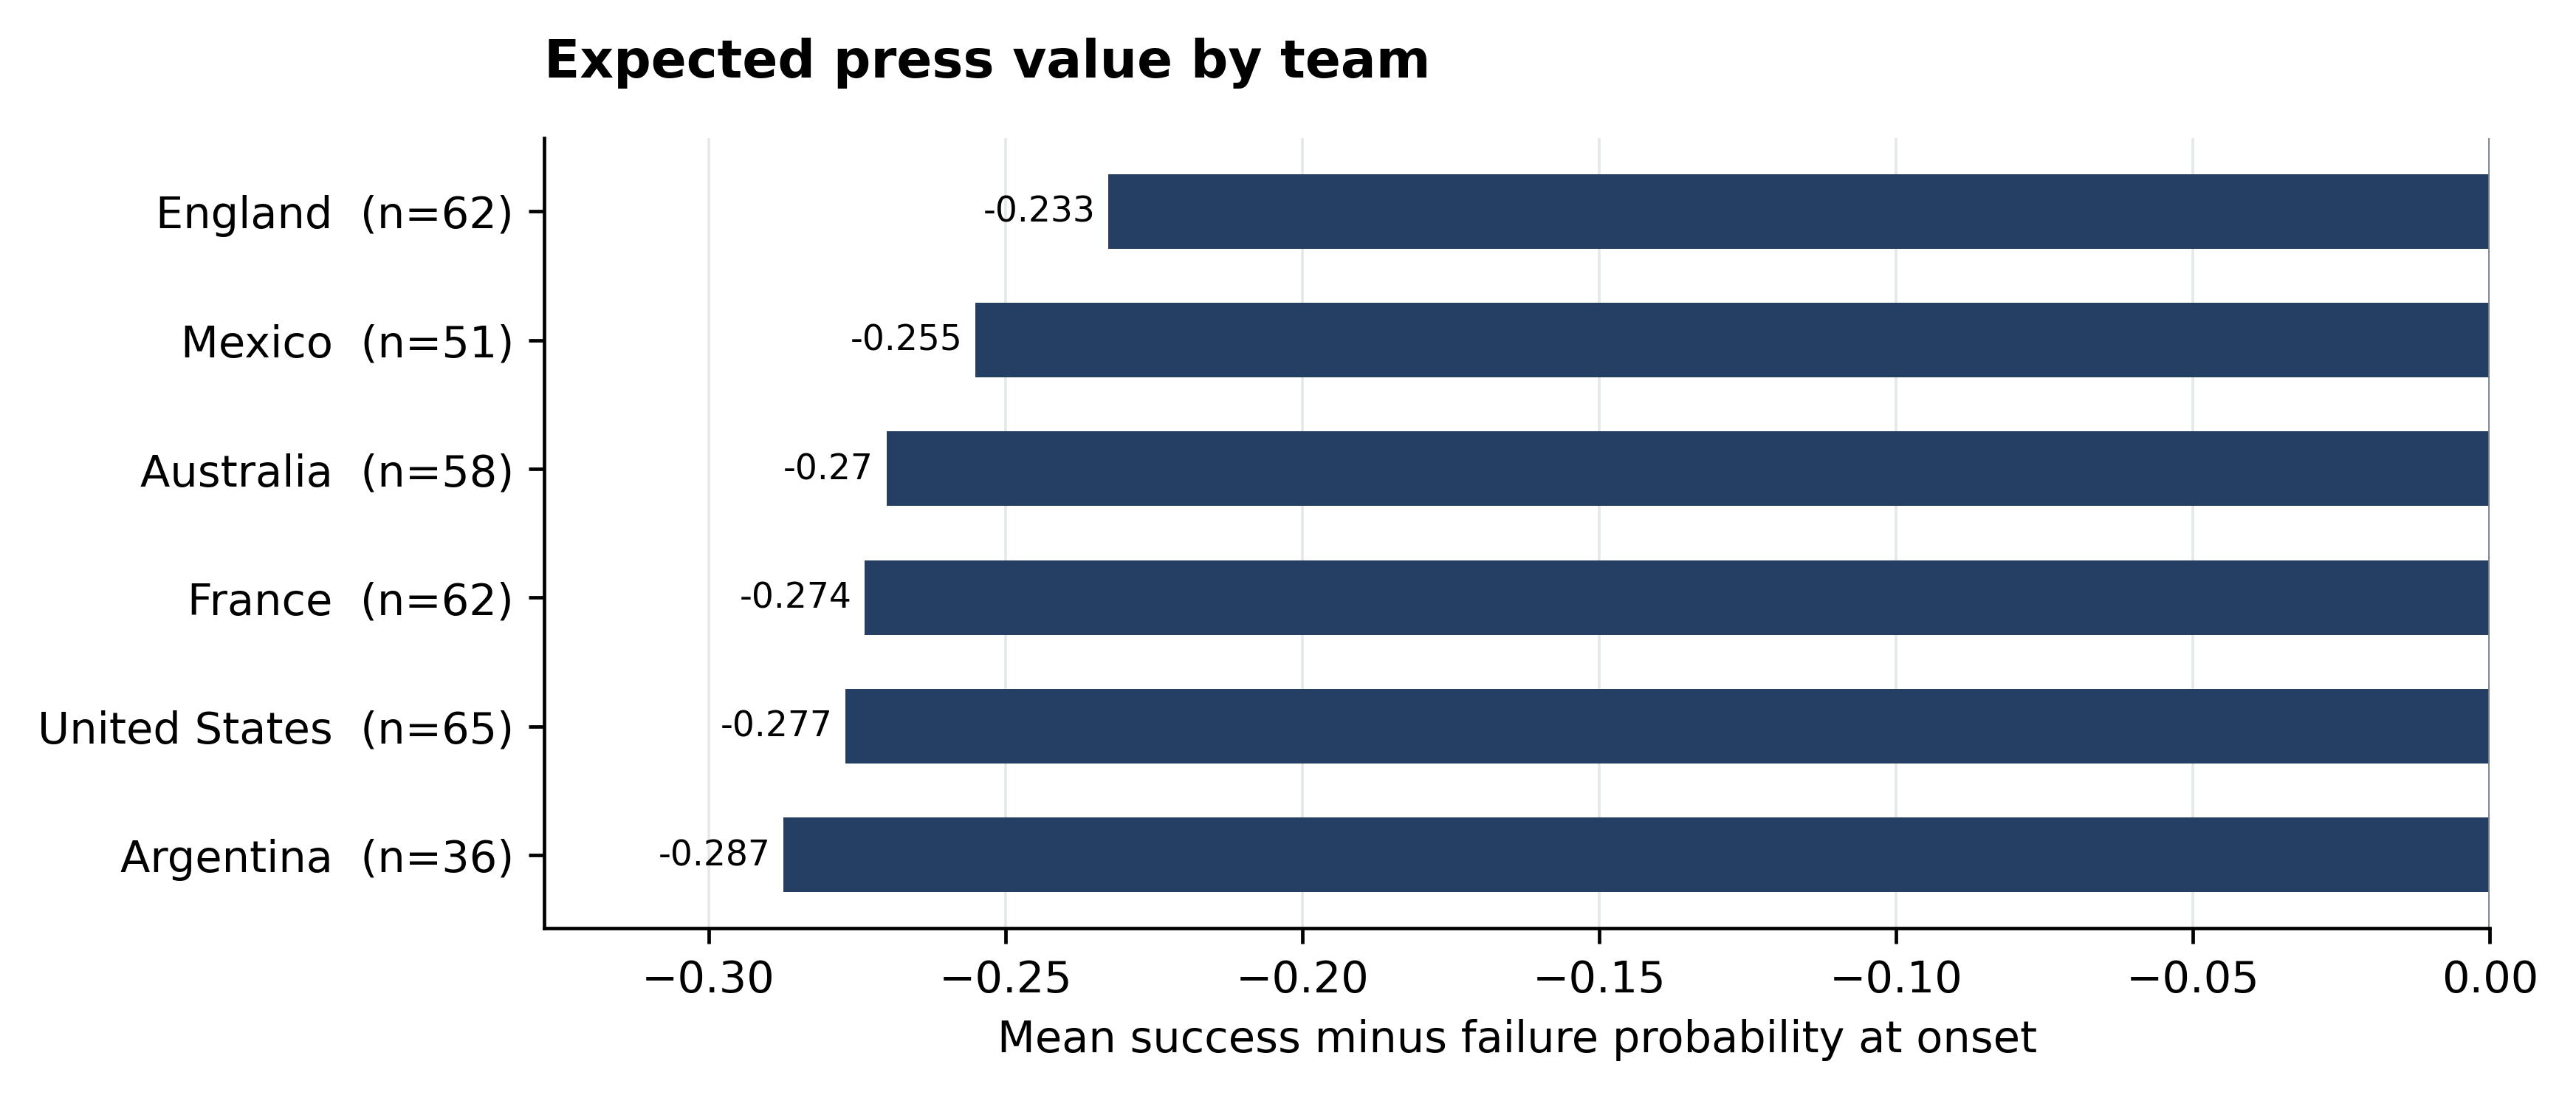

### Presser positioning by team · FIFA World Cup 2022 · 3 selected matches

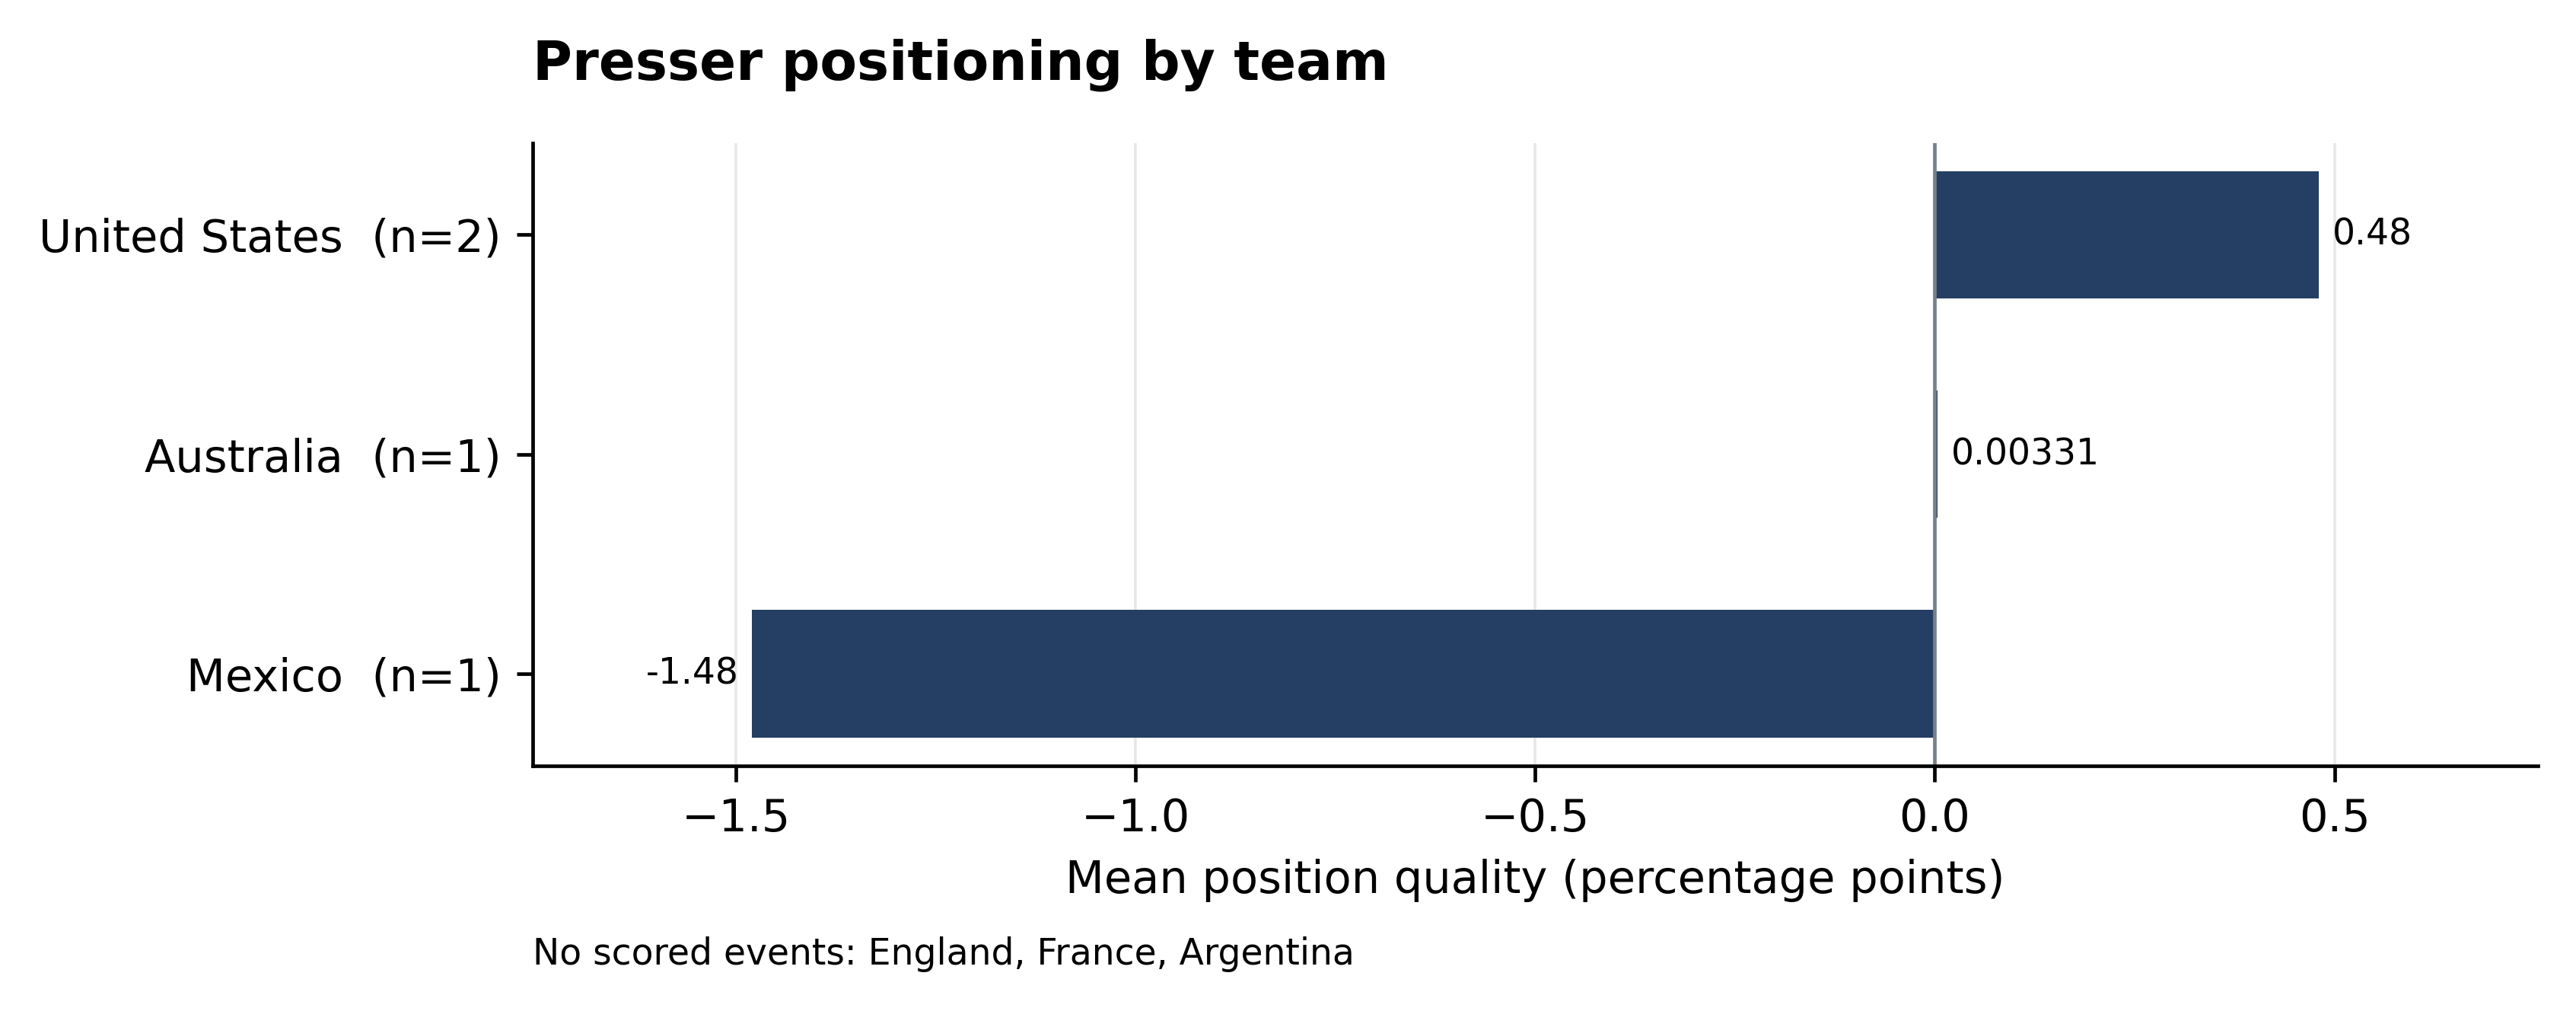

### Presser positioning by player · FIFA World Cup 2022 · 3 selected matches

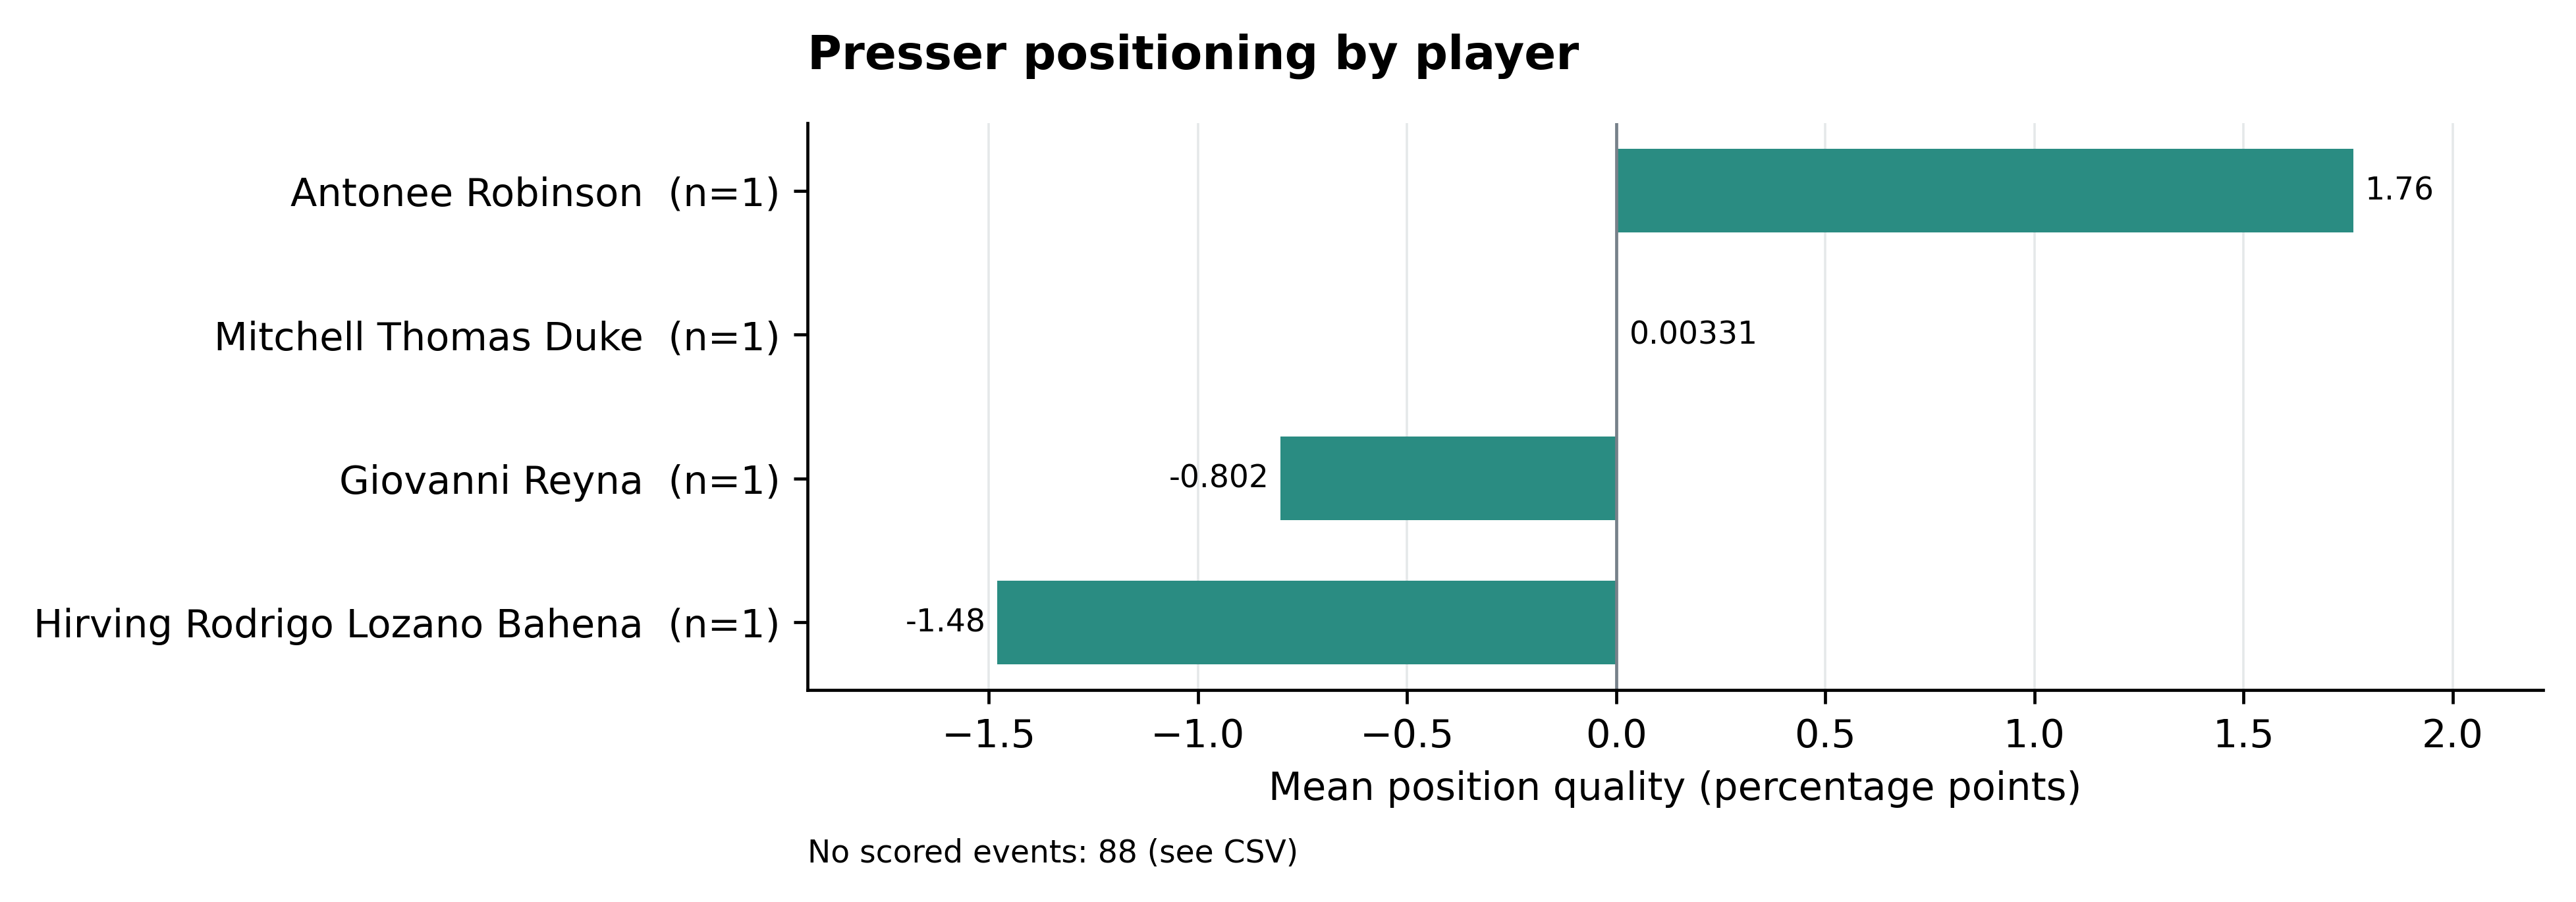

In [8]:
from spn.plotting import COMPARISONS, RANKINGS, TITLES, generate_plots

plot_dir = sample_dir / "plots"
plots = list(RANKINGS)
points_file = None
if INCLUDE_COMPARISONS:
    plots.extend(COMPARISONS)
    points_file = sample_dir / "selected_matches.json"
    points_file.write_text(json.dumps(list(fixtures.values())), encoding="utf-8")

report = generate_plots(plot_dir, input_source=matches_dir, events_dir=events_dir,
                        plots=plots, points=points_file, overwrite=True)
first = next(iter(fixtures.values()))
competition = first["competition"]["competition_name"]
fixture_count = "1 selected match" if len(fixtures) == 1 else f"{len(fixtures)} selected matches"
scope = f"{competition} {first['season']['season_name']} · {fixture_count}"
for key, item in report["plots"].items():
    caption = f"{TITLES[key]} · {scope}"
    display(Markdown(f"### {caption}"))
    if item["status"] == "skipped":
        print(item["reason"])
    else:
        display(Image(filename=str(plot_dir / f"{key}.png"), width=800, alt=caption),
                metadata={"alt": caption})